# 03 - Validation diagnostics

Three questions that a single RMSE number cannot answer:

1. **Is plain linear regression (OLS) a good reference point?** (the taught method, with no penalty)
2. **Is each model overfitting?** Compare error on the training engines with error on unseen validation engines.
3. **Where are the errors?** Plot error against true RUL. Errors near failure matter most.

Everything here uses the same engine-grouped folds as notebook 02. The test set is not used.
Cells marked **Your observation** are for you to complete.

## 1. Setup

In [3]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().resolve().parent))

from src.data_loader import add_rul, load_fd001
from src.evaluation import cross_validate, out_of_fold_predictions
from src.features import get_feature_columns
from src.models import baseline_models

train, _, _ = load_fd001()
train = add_rul(train)
CAP = 125
FEATURES = get_feature_columns()
models = baseline_models()

INCLUDE_RANDOM_FOREST = True   # set True to include it (slow: minutes)
names = ["mean", "linear", "ridge", "hist_gradient_boosting"]
if INCLUDE_RANDOM_FOREST:
    names.append("random_forest")
print(names)

['mean', 'linear', 'ridge', 'hist_gradient_boosting', 'random_forest']


## 2. Training error vs validation error

`train_rmse` is the error on the engines the model was fitted to. `rmse` is the error on engines it never saw.
A small `train_rmse` with a much larger `rmse` means the model has memorised noise (overfitting,
your notes section 5.1). A large error on both means it is too simple to capture the pattern (underfitting).

In [4]:
rows = {}
for name in names:
    res = cross_validate(models[name], train, FEATURES, cap=CAP)
    rows[name] = {
        "train_rmse": res["train_rmse"].mean(),
        "val_rmse": res["rmse"].mean(),
        "val_rmse_std": res["rmse"].std(),
        "gap (val - train)": res["rmse"].mean() - res["train_rmse"].mean(),
        "ratio (val / train)": res["rmse"].mean() / res["train_rmse"].mean(),
    }
gap_table = pd.DataFrame(rows).T.round(2)
gap_table

,train_rmse,val_rmse,val_rmse_std,gap (val - train),ratio (val / train)
mean,41.67,41.67,0.00,0.00,1.00
linear,21.47,21.66,1.54,0.19,1.01
ridge,21.47,21.66,1.54,0.19,1.01
hist_gradient_boosting,15.97,18.73,0.62,2.76,1.17
random_forest,6.83,18.87,0.68,12.04,2.76


**Your observation:** Which models fit the training engines much better than unseen engines?
Which look underfit (high error on both)? How does OLS compare with ridge? If they are almost
identical, what does that say about how much regularisation matters with 14 features and ~16,000 rows?
Link your answer to the overfit/underfit language in your notes.

## 3. Where are the errors? (out-of-fold predictions)

Every training row is predicted by a model that never saw that row's engine. Error = predicted - true,
so **positive means predicted too much remaining life (a late, dangerous prediction)** and negative
means too early.

In [5]:
oof = {name: out_of_fold_predictions(models[name], train, FEATURES, cap=CAP)
       for name in ["linear", "hist_gradient_boosting"]}
oof["hist_gradient_boosting"].head()

,engine,cycle,true,pred,error
0,1,1,125.0,120.078564,-4.921436
1,1,2,125.0,120.091353,-4.908647
2,1,3,125.0,121.447818,-3.552182
3,1,4,125.0,122.677886,-2.322114
4,1,5,125.0,119.609008,-5.390992


### 3a. Predicted vs true RUL

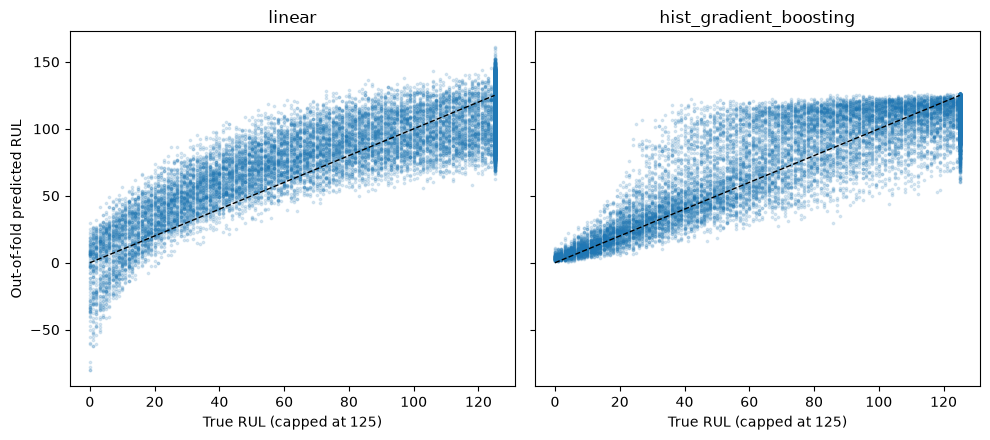

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, (name, df) in zip(axes, oof.items()):
    ax.scatter(df["true"], df["pred"], s=3, alpha=0.15)
    ax.plot([0, CAP], [0, CAP], "k--", lw=1)
    ax.set_title(name)
    ax.set_xlabel(f"True RUL (capped at {CAP})")
axes[0].set_ylabel("Out-of-fold predicted RUL")
fig.tight_layout()
plt.show()

### 3b. Error against true RUL

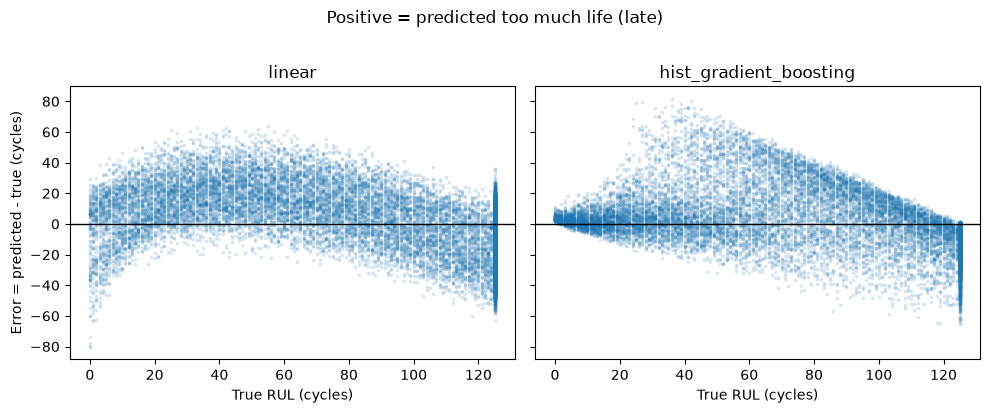

In [7]:
bins = [-1, 25, 50, 75, 100, CAP]
labels = ["0-25", "26-50", "51-75", "76-100", f"101-{CAP}"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (name, df) in zip(axes, oof.items()):
    ax.scatter(df["true"], df["error"], s=3, alpha=0.12)
    ax.axhline(0, color="k", lw=1)
    ax.set_title(name)
    ax.set_xlabel("True RUL (cycles)")
axes[0].set_ylabel("Error = predicted - true (cycles)")
fig.suptitle("Positive = predicted too much life (late)", y=1.02)
fig.tight_layout()
plt.show()

### 3c. Error by RUL band

In [8]:
def band_summary(df):
    band = pd.cut(df["true"], bins=bins, labels=labels)
    g = df.groupby(band, observed=True)["error"]
    return pd.DataFrame({
        "n": g.size(),
        "RMSE": g.apply(lambda e: float(np.sqrt(np.mean(e ** 2)))),
        "MAE": g.apply(lambda e: float(np.mean(np.abs(e)))),
        "mean error (bias)": g.mean(),
    })

for name, df in oof.items():
    print(name)
    display(band_summary(df).round(2))

linear


,n,RMSE,MAE,mean error (bias)
true,,,,
0-25,2600,20.64,16.84,6.93
26-50,2500,25.28,21.32,20.48
51-75,2500,23.74,19.68,17.52
76-100,2500,17.89,14.75,6.03
101-125,10531,21.35,17.37,-12.22


hist_gradient_boosting


,n,RMSE,MAE,mean error (bias)
true,,,,
0-25,2600,8.78,5.87,3.72
26-50,2500,24.74,17.05,12.09
51-75,2500,28.02,22.67,15.26
76-100,2500,21.07,18.09,8.61
101-125,10531,15.23,11.25,-9.87


**Your observation:** In which RUL band is each model most accurate and least accurate? Is the bias
(mean error) positive or negative in the bands close to failure? A model that is accurate on average but
late near failure is a problem for maintenance decisions. Are the large errors that raise RMSE above MAE
concentrated in particular bands? Note which model is better *in the 0-50 band*, even if another is
better overall.

### 3d. Per-engine view: are some engines much harder than others?

,rmse,bias
engine,,
57,38.1,29.2
65,37.8,27.9
90,37.8,27.5
61,32.1,21.6
24,30.8,21.5
16,30.4,-25.4
30,29.5,19.2
98,29.4,21.4


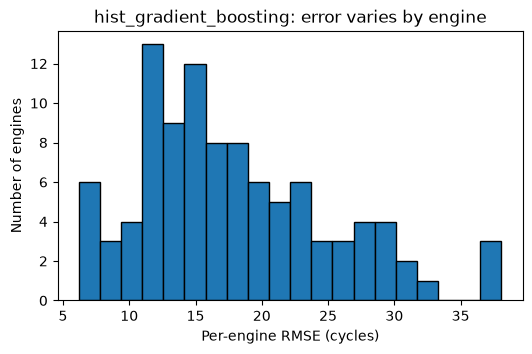

In [9]:
per_engine = (oof["hist_gradient_boosting"]
              .groupby("engine")["error"]
              .agg(rmse=lambda e: float(np.sqrt(np.mean(e ** 2))), bias="mean")
              .sort_values("rmse", ascending=False))
display(per_engine.head(8).round(1))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(per_engine["rmse"], bins=20, edgecolor="black")
ax.set_xlabel("Per-engine RMSE (cycles)")
ax.set_ylabel("Number of engines")
ax.set_title("hist_gradient_boosting: error varies by engine")
plt.show()

**Your observation:** Is the error spread fairly evenly across engines, or do a few engines dominate?
Pick the worst engine and plot its sensors (as in notebook 01) to see if something about it is unusual.
What does this suggest about how well 100 training engines represent the fleet?

## Summary (fill in)

| Question | Finding | Evidence |
| --- | --- | --- |
| Is OLS adequate vs ridge? |Yes, it is adequate. |As seen in 2., the values returned are the exact same. However, gradient boosting beats both, and linear underfits.|
| Which models overfit? |Random forest strongly; gradient boosting slightly| Random forest: training RMSE 6.83 against validation 18.87 (gap 12.04). Gradient boosting: 15.97 against 18.73 (gap 2.76). Linear and ridge do not overfit (gap 0.19); they underfit because they are too simple.|
| Where is error highest (RUL band)? | 26-75 (51-75 for gradient boosting, 26-50 for linear)|Table 3c: gradient boosting RMSE is 28.0 in the 51-75 band and 24.7 in 26-50. Linear is 25.3 in 26-50 and 23.7 in 51-75. Gradient boosting is most accurate in the 0-25 band (RMSE 8.8).|
| Early or late bias near failure? |Late bias near failure, largest at 26-75 | Table 3c: in the 0-25 band the mean error is positive (+3.7 gradient boosting, +6.9 linear), meaning too much life predicted (late, the dangerous direction). It is largest at 26-75 (+12 to +20). Only the 101-125 band is early (about -10 to -12).|